# Student Performance: Regression and Classification

This notebook compares simple linear regression, multiple linear regression, and logistic regression using a reproducible synthetic dataset of exactly 5,000 students.

## Dataset and models

The synthetic records contain study hours, attendance, completed practice questions, and a previous exam score. The continuous `exam_score` target is generated from these predictors plus random noise and bounded to the 0-100 range. The binary `pass_status` target is based on a score threshold of 60.

Simple linear regression uses study hours alone. Multiple linear regression uses all four predictors. Logistic regression predicts pass/fail from those same four predictors, excluding `exam_score` to prevent target leakage.

Regression performance is reported with MAE, MSE, RMSE, and R-squared. Classification performance is reported with accuracy, precision, recall, and F1 score.

Dataset observations: 5,000
Pass rate: 0.853


,study_hours,attendance_percentage,practice_questions_completed,previous_exam_score,exam_score,pass_status
0,5.119941,69.681776,40.495878,67.478566,62.11,1
1,11.457857,73.671783,36.626649,83.538540,92.14,1
2,9.051933,92.727370,21.734622,71.573341,88.05,1
3,7.585243,67.000219,62.690334,40.414668,60.03,1
4,2.716205,93.482484,50.279295,47.062715,71.96,1


Regression model comparison (test set)


,Model,MAE,MSE,RMSE,R-squared
0,Simple Linear Regression,8.8758,117.9664,10.8612,0.3510
1,Multiple Linear Regression,4.5943,33.5396,5.7913,0.8155


Logistic regression metrics (test set)


,Metric,Value
0,Accuracy,0.9230
1,Precision,0.9360
2,Recall,0.9766
3,F1 Score,0.9558


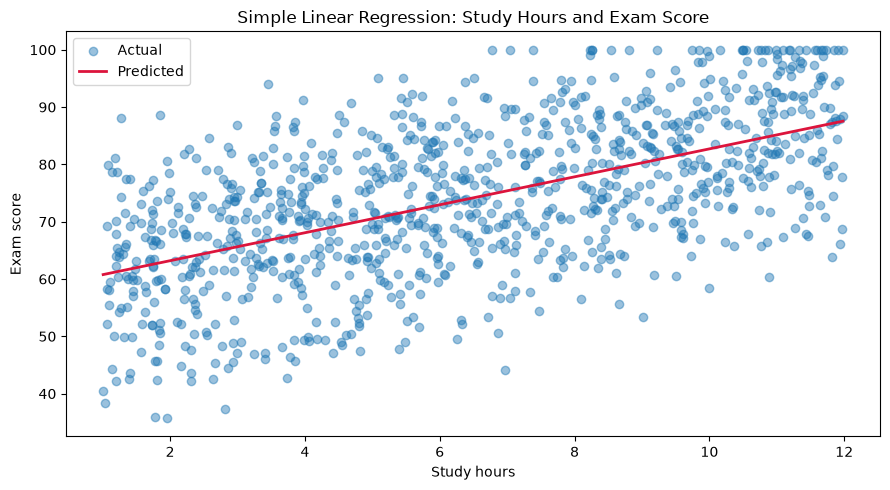

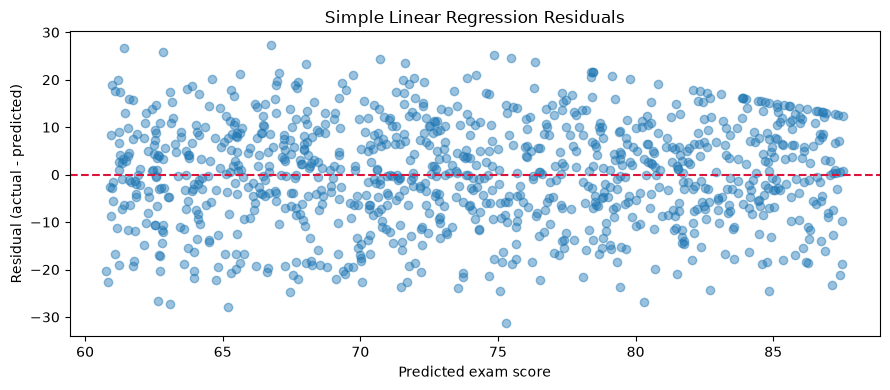

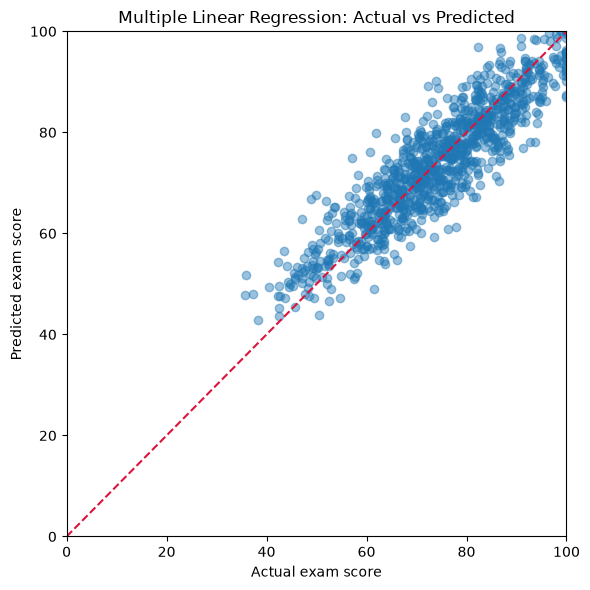

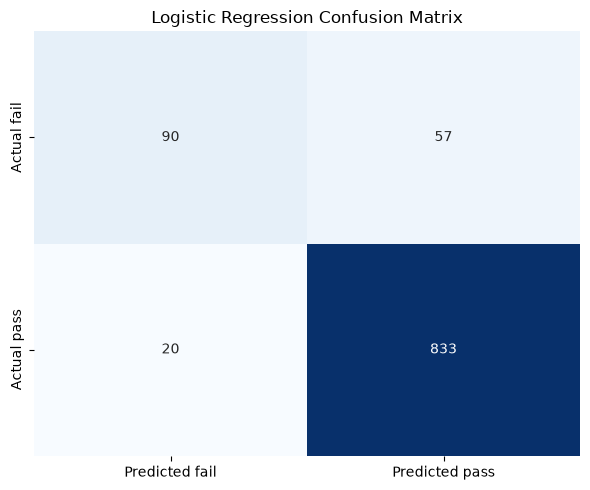

Class counts (0 = fail, 1 = pass):
pass_status
0     736
1    4264


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
n_samples = 5000

student_data = pd.DataFrame({
    'study_hours': np.random.uniform(1, 12, n_samples),
    'attendance_percentage': np.random.uniform(50, 100, n_samples),
    'practice_questions_completed': np.random.uniform(5, 100, n_samples),
    'previous_exam_score': np.random.uniform(35, 100, n_samples),
})
noise = np.random.normal(0, 6, n_samples)
student_data['exam_score'] = np.clip(
    5
    + 2.5 * student_data['study_hours']
    + 0.25 * student_data['attendance_percentage']
    + 0.20 * student_data['practice_questions_completed']
    + 0.35 * student_data['previous_exam_score']
    + noise,
    0,
    100,
).round(2)
student_data['pass_status'] = (student_data['exam_score'] >= 60).astype(int)

assert len(student_data) == 5000
assert student_data['pass_status'].nunique() == 2
print(f'Dataset observations: {len(student_data):,}')
print(f'Pass rate: {student_data["pass_status"].mean():.3f}')
display(student_data.head())

features = [
    'study_hours',
    'attendance_percentage',
    'practice_questions_completed',
    'previous_exam_score',
]
X_simple = student_data[['study_hours']]
X_multiple = student_data[features]
y_score = student_data['exam_score']
y_pass = student_data['pass_status']

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple, y_score, test_size=0.2, random_state=RANDOM_STATE
)
X_train_multiple, X_test_multiple, y_train_multiple, y_test_multiple = train_test_split(
    X_multiple, y_score, test_size=0.2, random_state=RANDOM_STATE
)
X_train_logistic, X_test_logistic, y_train_logistic, y_test_logistic = train_test_split(
    X_multiple, y_pass, test_size=0.2, random_state=RANDOM_STATE, stratify=y_pass
)

# Simple linear regression
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)
simple_predictions = simple_model.predict(X_test_simple)

# Multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_multiple, y_train_multiple)
multiple_predictions = multiple_model.predict(X_test_multiple)

regression_metrics = pd.DataFrame([
    {
        'Model': 'Simple Linear Regression',
        'MAE': mean_absolute_error(y_test_simple, simple_predictions),
        'MSE': mean_squared_error(y_test_simple, simple_predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test_simple, simple_predictions)),
        'R-squared': r2_score(y_test_simple, simple_predictions),
    },
    {
        'Model': 'Multiple Linear Regression',
        'MAE': mean_absolute_error(y_test_multiple, multiple_predictions),
        'MSE': mean_squared_error(y_test_multiple, multiple_predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test_multiple, multiple_predictions)),
        'R-squared': r2_score(y_test_multiple, multiple_predictions),
    },
]).round(4)
print('Regression model comparison (test set)')
display(regression_metrics)

# Logistic regression uses predictors only; exam_score is intentionally excluded.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
)
logistic_model.fit(X_train_logistic, y_train_logistic)
logistic_predictions = logistic_model.predict(X_test_logistic)
classification_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [
        accuracy_score(y_test_logistic, logistic_predictions),
        precision_score(y_test_logistic, logistic_predictions, zero_division=0),
        recall_score(y_test_logistic, logistic_predictions, zero_division=0),
        f1_score(y_test_logistic, logistic_predictions, zero_division=0),
    ],
}).round(4)
print('Logistic regression metrics (test set)')
display(classification_metrics)

# Visualize the simple regression fit and residuals.
simple_order = np.argsort(X_test_simple['study_hours'].to_numpy())
plt.figure(figsize=(9, 5))
plt.scatter(X_test_simple['study_hours'], y_test_simple, alpha=0.45, label='Actual')
plt.plot(
    X_test_simple['study_hours'].to_numpy()[simple_order],
    simple_predictions[simple_order], color='crimson', linewidth=2, label='Predicted',
)
plt.title('Simple Linear Regression: Study Hours and Exam Score')
plt.xlabel('Study hours')
plt.ylabel('Exam score')
plt.legend()
plt.tight_layout()
plt.show()

simple_residuals = y_test_simple - simple_predictions
plt.figure(figsize=(9, 4))
plt.scatter(simple_predictions, simple_residuals, alpha=0.45)
plt.axhline(0, color='crimson', linestyle='--')
plt.title('Simple Linear Regression Residuals')
plt.xlabel('Predicted exam score')
plt.ylabel('Residual (actual - predicted)')
plt.tight_layout()
plt.show()

# Compare multiple-regression predictions with actual scores.
plt.figure(figsize=(6, 6))
plt.scatter(y_test_multiple, multiple_predictions, alpha=0.45)
plt.plot([0, 100], [0, 100], color='crimson', linestyle='--')
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.xlabel('Actual exam score')
plt.ylabel('Predicted exam score')
plt.tight_layout()
plt.show()

confusion = confusion_matrix(y_test_logistic, logistic_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Predicted fail', 'Predicted pass'],
    yticklabels=['Actual fail', 'Actual pass'],
)
plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()

print('Class counts (0 = fail, 1 = pass):')
print(student_data['pass_status'].value_counts().sort_index().to_string())

## Results, discussion, and conclusion

On the held-out test set, multiple linear regression performed better than simple linear regression. Its MAE was 4.5943 and its R-squared was 0.8155, compared with an MAE of 8.8758 and an R-squared of 0.3510 for the model using study hours alone. This indicates that the other generated predictors provide useful information about exam scores.

Logistic regression achieved 0.9230 accuracy and an F1 score of 0.9558 for predicting passes. The dataset is imbalanced: 4,264 students pass and 736 fail. The confusion matrix shows 57 failing students predicted as passes and 20 passing students predicted as failures, so accuracy should be interpreted alongside the class counts and other classification metrics.

The visualizations are consistent with these metrics: the simple-regression plot has substantial scatter around its fitted line, while multiple-regression predictions cluster more closely around the actual-equals-predicted line. The classification confusion matrix makes the two types of prediction error visible.

These results demonstrate the model comparison on controlled synthetic data, not evidence about real student outcomes. The score formula, noise level, and pass threshold determine the observed performance; real-world data could have different relationships and error patterns.